In [13]:
import warnings
warnings.simplefilter("ignore")


from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


In [14]:
df_pulito= pd.read_parquet('df_pulito.parquet')
df_unlearn=df_pulito.drop(['risultati'], axis=1).copy()

standard_scaler = StandardScaler().set_output(transform="pandas")

y_da_binarizzare= np.array(df_unlearn['sii'])
y_pulito = np.where(y_da_binarizzare >= 3.0, 1, 0)
pciat_cols = [f"PCIAT-PCIAT_{i:02d}" for i in range(1, 21)]
X_pulito = df_unlearn.drop(columns=['id','sii','PCIAT-PCIAT_Total']).copy() #+pciat_cols

X_pulito_s = pd.DataFrame(
    standard_scaler.fit_transform(X_pulito), 
    columns=X_pulito.columns, 
    index=X_pulito.index
)

X_trainp, X_testp, y_trainp, y_testp = train_test_split(X_pulito, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

#dati standardizzati, servivano solo per tomek
X_trainp_s, X_testp_s, y_trainp_s, y_testp_s = train_test_split(X_pulito_s, y_pulito, test_size=0.3, random_state=100, stratify=y_pulito)

In [15]:
print(pd.Series(y_testp_s).value_counts())
print(pd.Series(y_trainp_s).value_counts())
print(pd.Series(y_pulito).value_counts())

percentuali = pd.Series(y_pulito).value_counts(normalize=True) * 100
print(percentuali)
X_trainp_s.columns
# iperparametri decisiontree

0    2443
1      25
Name: count, dtype: int64
0    5698
1      59
Name: count, dtype: int64
0    8141
1      84
Name: count, dtype: int64
0    98.978723
1     1.021277
Name: proportion, dtype: float64


Index(['Basic_Demos-Enroll_Season', 'Basic_Demos-Age', 'Basic_Demos-Sex',
       'CGAS-Season', 'CGAS-CGAS_Score', 'Physical-Season', 'Physical-Height',
       'Physical-Weight', 'Physical-Waist_Circumference',
       'Physical-Diastolic_BP', 'Physical-HeartRate', 'Physical-Systolic_BP',
       'Fitness_Endurance-Season', 'Fitness_Endurance-Max_Stage', 'FGC-Season',
       'FGC-FGC_CU', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND', 'FGC-FGC_GSND_Zone',
       'FGC-FGC_GSD', 'FGC-FGC_GSD_Zone', 'FGC-FGC_PU', 'FGC-FGC_PU_Zone',
       'FGC-FGC_SRL', 'FGC-FGC_SRL_Zone', 'FGC-FGC_SRR', 'FGC-FGC_SRR_Zone',
       'FGC-FGC_TL', 'FGC-FGC_TL_Zone', 'BIA-Season',
       'BIA-BIA_Activity_Level_num', 'BIA-BIA_BMC', 'BIA-BIA_BMR',
       'BIA-BIA_DEE', 'BIA-BIA_ECW', 'BIA-BIA_FFM', 'BIA-BIA_FFMI',
       'BIA-BIA_FMI', 'BIA-BIA_Fat', 'BIA-BIA_Frame_num', 'BIA-BIA_ICW',
       'BIA-BIA_LDM', 'BIA-BIA_LST', 'BIA-BIA_SMM', 'BIA-BIA_TBW',
       'PCIAT-Season', 'PCIAT-PCIAT_01', 'PCIAT-PCIAT_02', 'PCIAT-PCIAT_0

In [16]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# Definizione dello spazio degli iperparametri da esplorare
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 3, 5,10],
    'class_weight': [None, 'balanced']
}

dt = DecisionTreeClassifier(random_state=42)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Configuriamo la RandomizedSearch. Usiamo 'f1' come metrica visto lo sbilanciamento
random_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_dist,
    n_iter=20,          # Numero di combinazioni casuali da testare
    scoring='f1',       # Ottimizziamo per la classe minoritaria
    cv=cv_strat,        # Stratified 5-fold cross validation
    random_state=42,
    n_jobs=-1
)

print("Avvio RandomizedSearchCV per DecisionTreeClassifier...")
random_search.fit(X_trainp_s, y_trainp_s)

print("\nMigliori iperparametri trovati:")
print(random_search.best_params_)
print(f"Miglior F1-score (Cross-Validation): {random_search.best_score_:.4f}")

# Salviamo il modello ottimizzato
best_clf = random_search.best_estimator_


Avvio RandomizedSearchCV per DecisionTreeClassifier...

Migliori iperparametri trovati:
{'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': None, 'criterion': 'gini', 'class_weight': None}
Miglior F1-score (Cross-Validation): 0.1796


In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

from sklearn.base import clone
clf = clone(best_clf)
clf.fit(X_trainp_s, y_trainp_s)

y_pred0 = clf.predict(X_testp_s)

print('Accuracy %s' % accuracy_score(y_testp_s, y_pred0))
print('F1-score %s' % f1_score(y_testp_s, y_pred0, average=None))
print(classification_report(y_testp_s, y_pred0))

importances = pd.Series(clf.feature_importances_, index=X_trainp_s.columns)
print(importances.sort_values(ascending=False).head(5))

#PCIAT-PCIAT_Total            0.942548
#praticamente viene usata solo questa per fare gli split quindi va levata? suppongo

'''Ho rimosso la variabile #PCIAT-PCIAT_Total perché introduceva Target Leakage. Essendo il target una discretizzazione 
del punteggio totale, lasciarla avrebbe reso il problema banale, portando il modello a imparare una semplice regola aritmetica 
anziché i pattern comportamentali sottostanti. Rimuovendola, ho forzato il modello a lavorare sui singoli item, aumentando il valore 
diagnostico e la capacità di generalizzazione su nuovi soggetti di cui potremmo avere solo risposte parziali.

Senza il totale, il Decision Tree inizierà a pesare i singoli comportamenti. 
Scoprirai, ad esempio, che la domanda 20 ("Quanto spesso preferisci stare su internet invece di uscire con gli amici?")
pesa molto più della domanda 4.
Interpretabilità: Potrai dire: "Il modello ha individuato che non è il punteggio totale a contare, ma questi 4 comportamenti specifici 
che, se presenti contemporaneamente, portano alla classe 3".'''

Accuracy 0.9910858995137763
F1-score [0.99550654 0.45      ]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2443
           1       0.60      0.36      0.45        25

    accuracy                           0.99      2468
   macro avg       0.80      0.68      0.72      2468
weighted avg       0.99      0.99      0.99      2468

PCIAT-PCIAT_14                0.149230
PCIAT-PCIAT_08                0.115331
Physical-Weight               0.086214
SDS-SDS_Total_Raw             0.059161
BIA-BIA_Activity_Level_num    0.052327
dtype: float64


'Ho rimosso la variabile #PCIAT-PCIAT_Total perché introduceva Target Leakage. Essendo il target una discretizzazione \ndel punteggio totale, lasciarla avrebbe reso il problema banale, portando il modello a imparare una semplice regola aritmetica \nanziché i pattern comportamentali sottostanti. Rimuovendola, ho forzato il modello a lavorare sui singoli item, aumentando il valore \ndiagnostico e la capacità di generalizzazione su nuovi soggetti di cui potremmo avere solo risposte parziali.\n\nSenza il totale, il Decision Tree inizierà a pesare i singoli comportamenti. \nScoprirai, ad esempio, che la domanda 20 ("Quanto spesso preferisci stare su internet invece di uscire con gli amici?")\npesa molto più della domanda 4.\nInterpretabilità: Potrai dire: "Il modello ha individuato che non è il punteggio totale a contare, ma questi 4 comportamenti specifici \nche, se presenti contemporaneamente, portano alla classe 3".'

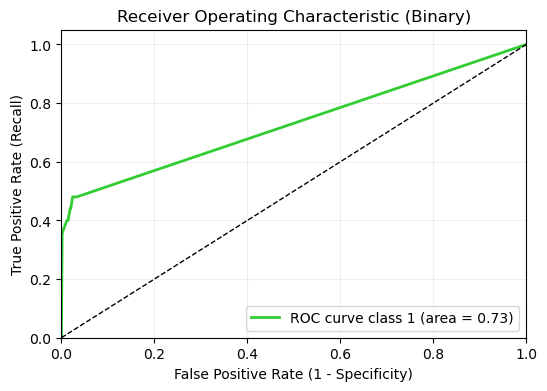

In [18]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

y_score0 = clf.predict_proba(X_testp_s)[:, 1]
fpr0, tpr0, thresholds0 = roc_curve(y_testp_s, y_score0)
roc_auc0 = auc(fpr0, tpr0)

plt.figure(figsize=(6, 4))
plt.plot(fpr0, tpr0, color='limegreen', lw=2, 
         label=f'ROC curve class 1 (area = {roc_auc0:.2f})')

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (Binary)')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

In [19]:
# storing class 1 ROC curve for successive comparisons
def plot_ROC_comparison(fpr, tpr):
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr0, tpr0, color='darkorange', lw=3, label='$AUC_0$ = %.3f' % (roc_auc0))
    plt.plot(fpr, tpr, color='green', lw=3, label='$AUC_1$ = %.3f' % (roc_auc))
    
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=16)
    plt.ylabel('True Positive Rate', fontsize=16)
    plt.title('ROC curve', fontsize=16)
    plt.legend(loc="lower right", fontsize=14, frameon=False)
    plt.tick_params(axis='both', which='major', labelsize=16)
    plt.show()

def plot_pca(X_pca, y_train):
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
    plt.show()

In [20]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN

## Scelte finali

1. Undersampling: CondensedNearestNeighbour
2. Oversampling: SMOTE o ADASYN
3. Balancing at the Algorithm Level: Class Weight

Resampled dataset shape Counter({np.int64(0): 538, np.int64(1): 59})


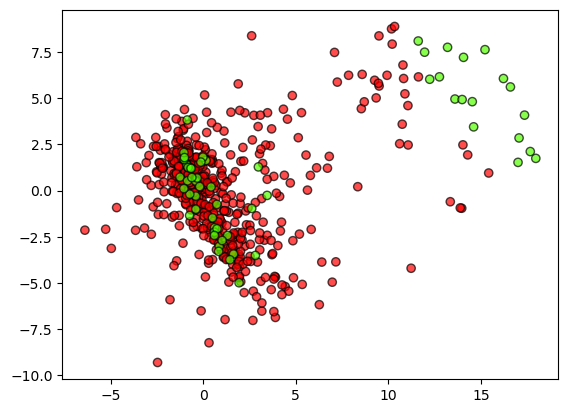

Accuracy 0.9773095623987034
F1-score [0.98847262 0.28205128]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      2443
           1       0.21      0.44      0.28        25

    accuracy                           0.98      2468
   macro avg       0.60      0.71      0.64      2468
weighted avg       0.99      0.98      0.98      2468



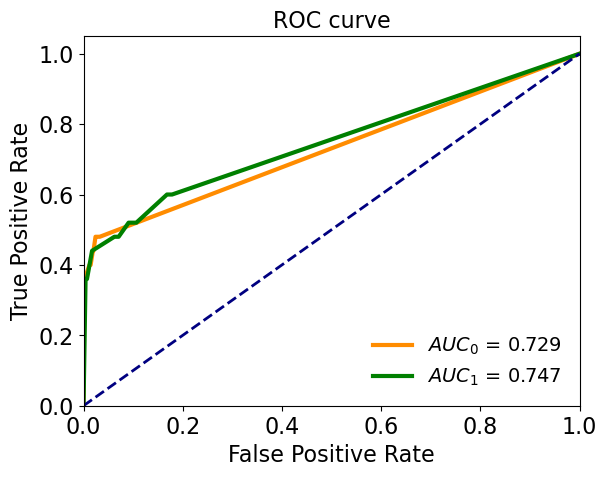

In [21]:
# --- CondensedNearestNeighbour ---

cnn = CondensedNearestNeighbour(random_state=42, n_neighbors=1, n_jobs=-1)
X_res, y_res = cnn.fit_resample(X_trainp_s, y_trainp_s)
print('Resampled dataset shape %s' % Counter(y_res))
pca = PCA(n_components=2)
pca.fit(X_trainp_s)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

# fit
clf = clone(best_clf)
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp_s)
print('Accuracy %s' % accuracy_score(y_testp_s, y_pred))
print('F1-score %s' % f1_score(y_testp_s, y_pred, average=None))
print(classification_report(y_testp_s, y_pred))

# roc
y_score = clf.predict_proba(X_testp_s)
#plot_roc(y_testp_s, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp_s, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)

Resampled dataset shape Counter({np.int64(0): 5698, np.int64(1): 5697})


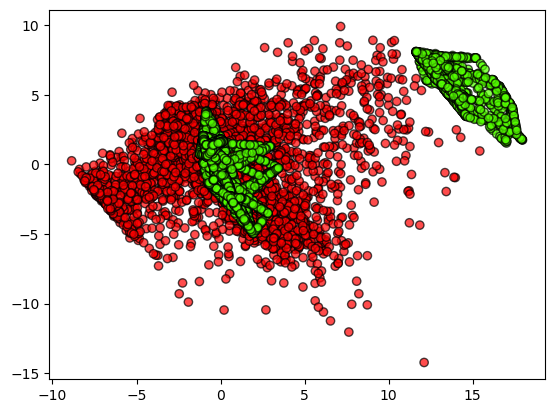

Accuracy 0.9785251215559158
F1-score [0.98912821 0.13114754]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2443
           1       0.11      0.16      0.13        25

    accuracy                           0.98      2468
   macro avg       0.55      0.57      0.56      2468
weighted avg       0.98      0.98      0.98      2468



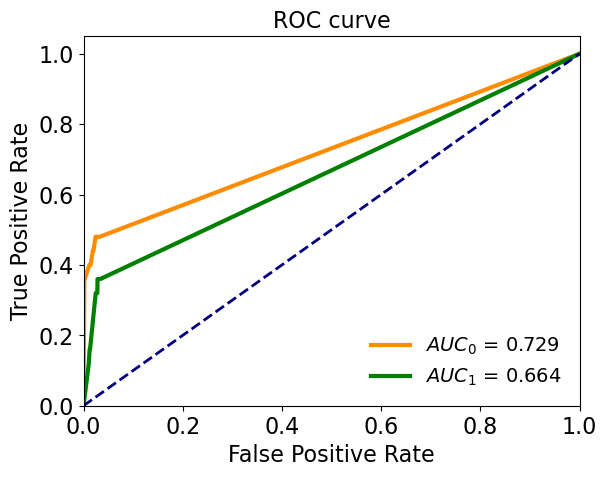

In [22]:
# --- ADASYN ---

ada = ADASYN(random_state=42)
X_res, y_res = ada.fit_resample(X_trainp_s, y_trainp_s)
#guidotti non mette i train ma X e y complete quindi boh controlla
print('Resampled dataset shape %s' % Counter(y_res))

pca = PCA(n_components=2)
pca.fit(X_trainp_s)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp_s)
print('Accuracy %s' % accuracy_score(y_testp_s, y_pred))
print('F1-score %s' % f1_score(y_testp_s, y_pred, average=None))
print(classification_report(y_testp_s, y_pred))

# roc
y_score = clf.predict_proba(X_testp_s)
#plot_roc(y_testp_s, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp_s, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)



Resampled dataset shape Counter({np.int64(0): 5698, np.int64(1): 5698})


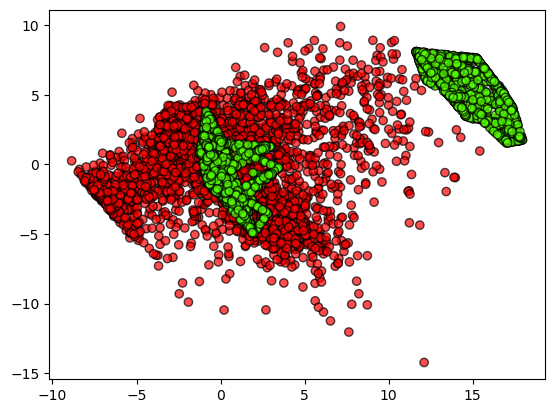

Accuracy 0.976904376012966
F1-score [0.98829328 0.14925373]
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      2443
           1       0.12      0.20      0.15        25

    accuracy                           0.98      2468
   macro avg       0.56      0.59      0.57      2468
weighted avg       0.98      0.98      0.98      2468



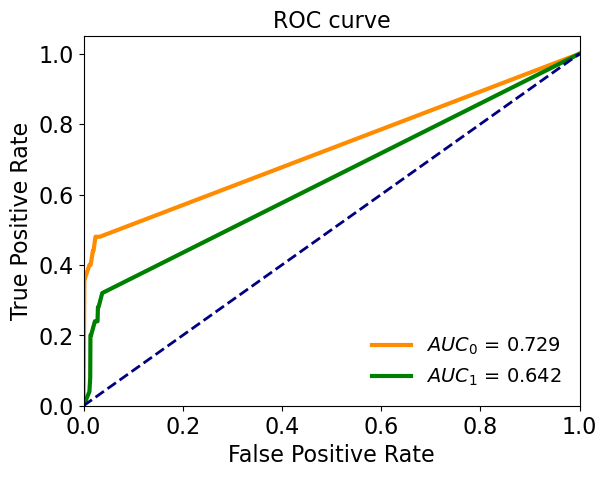

In [23]:
# --- SMOTE ---

sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_trainp_s, y_trainp_s)
print('Resampled dataset shape %s' % Counter(y_res))

pca = PCA(n_components=2)
pca.fit(X_trainp_s)
X_pca = pca.transform(X_res)
plot_pca(X_pca, y_res)

# fit
clf.fit(X_res, y_res)

# predict
y_pred = clf.predict(X_testp_s)
print('Accuracy %s' % accuracy_score(y_testp_s, y_pred))
print('F1-score %s' % f1_score(y_testp_s, y_pred, average=None))
print(classification_report(y_testp_s, y_pred))

# roc
y_score = clf.predict_proba(X_testp_s)
#plot_roc(y_testp_s, y_score)
plt.show()

# roc comparison
fpr, tpr, _ = roc_curve(y_testp_s, y_score[:, 1])
plot_ROC_comparison(fpr, tpr)



### Scelta Parametri: Class Weight (Algorithmic Balancing)
**Logica della scelta:**
Il bilanciamento tramite pesi agisce direttamente sulla funzione di costo del Decision Tree. È un metodo che non altera i dati originali (niente undersampling o oversampling) ed è spesso più robusto e veloce. 
Il parametro chiave nel `DecisionTreeClassifier` è `class_weight`. 
- `class_weight='balanced'` calcola i pesi in modo inversamente proporzionale alle frequenze (es. assegnerà un peso circa 100 volte superiore alla classe minoritaria).
- Proveremo anche dei pesi custom: `{0: 1, 1: 50}` e `{0: 1, 1: 150}` per penalizzare in modo asimmetrico i falsi negativi.

## Riassunto dei Risultati e Confronto Finale
In questa sezione alleniamo i modelli con i parametri ottimali emersi dal tuning e raccogliamo tutte le metriche, le curve ROC e le Matrici di Confusione in un'unica vista per facilitare il confronto.

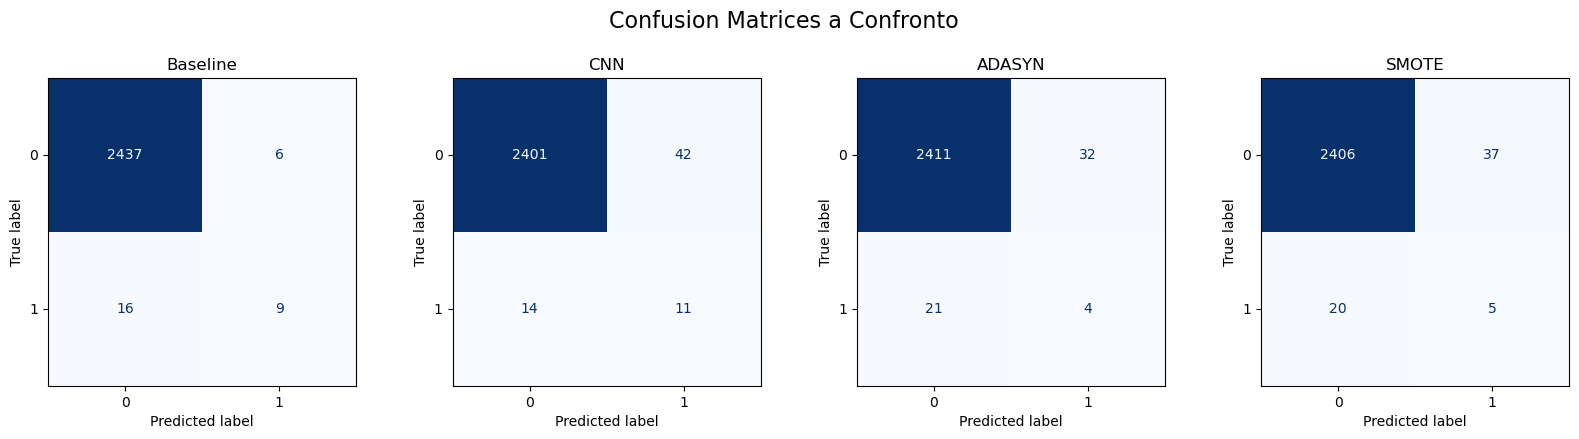

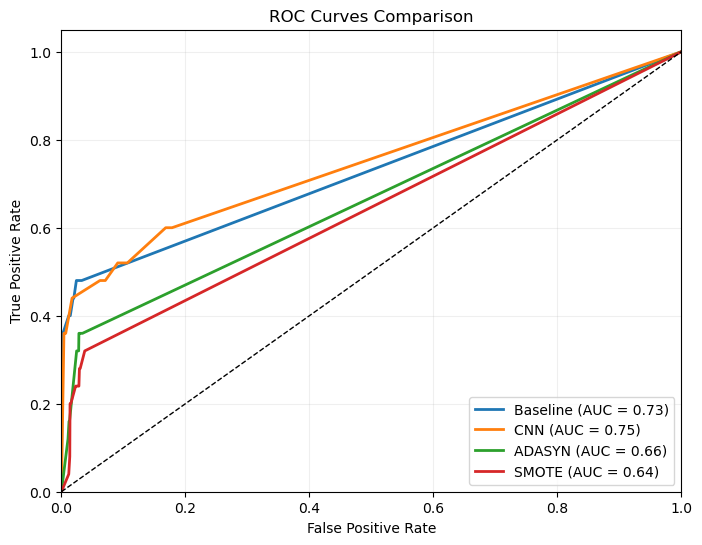

,Accuracy,Precision (Cl. 0),Recall (Cl. 0),F1-Score (Cl. 0),Precision (Cl. 1),Recall (Cl. 1),F1-Score (Cl. 1),ROC AUC
Baseline,0.991,0.993,0.998,0.996,0.600,0.36,0.450,0.729
CNN,0.977,0.994,0.983,0.988,0.208,0.44,0.282,0.747
ADASYN,0.979,0.991,0.987,0.989,0.111,0.16,0.131,0.664
SMOTE,0.977,0.992,0.985,0.988,0.119,0.20,0.149,0.642


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.over_sampling import ADASYN, SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

# Dizionario per salvare i risultati
results = {}

# Definiamo i metodi con i parametri scelti dal tuning (es. valori di default/ottimali)
methods = {
    'Baseline': (None, clone(best_clf)),
    'CNN': (CondensedNearestNeighbour(random_state=42, n_neighbors=1, n_jobs=-1), clone(best_clf)),
    'ADASYN': (ADASYN(random_state=42, n_neighbors=5), clone(best_clf)),
    'SMOTE': (SMOTE(random_state=42, k_neighbors=5), clone(best_clf))
}

fig_cm, axes = plt.subplots(1, 4, figsize=(20, 4))  # 4 plots instead of 5
fig_cm.suptitle('Confusion Matrices a Confronto', fontsize=16, y=1.05)

plt.figure(figsize=(8, 6)) # Per la curva ROC

for i, (name, (sampler, clf)) in enumerate(methods.items()):
    # Resampling
    if sampler:
        X_res, y_res = sampler.fit_resample(X_trainp_s, y_trainp_s)
    else:
        X_res, y_res = X_trainp_s, y_trainp_s
        
    # Fit
    clf.fit(X_res, y_res)
    
    # Predict
    y_pred = clf.predict(X_testp_s)
    y_score = clf.predict_proba(X_testp_s)[:, 1]
    
    # Metriche
    acc = accuracy_score(y_testp_s, y_pred)
    f1_min = f1_score(y_testp_s, y_pred, pos_label=1)
    f1_maj = f1_score(y_testp_s, y_pred, pos_label=0)
    prec_min = precision_score(y_testp_s, y_pred, pos_label=1, zero_division=0)
    rec_min = recall_score(y_testp_s, y_pred, pos_label=1, zero_division=0)
    prec_maj = precision_score(y_testp_s, y_pred, pos_label=0, zero_division=0)
    rec_maj = recall_score(y_testp_s, y_pred, pos_label=0, zero_division=0)
    
    # ROC
    fpr, tpr, _ = roc_curve(y_testp_s, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')
    
    # Confusion Matrix
    cm = confusion_matrix(y_testp_s, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name)
    
    # Salva in dict
    results[name] = {
        'Accuracy': round(acc, 3),
        'Precision (Cl. 0)': round(prec_maj, 3),
        'Recall (Cl. 0)': round(rec_maj, 3),
        'F1-Score (Cl. 0)': round(f1_maj, 3),
        'Precision (Cl. 1)': round(prec_min, 3),
        'Recall (Cl. 1)': round(rec_min, 3),
        'F1-Score (Cl. 1)': round(f1_min, 3),
        'ROC AUC': round(roc_auc, 3)
    }

# Mostra ROC
plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

# Mostra Confusion Matrices
plt.show()

# Tabella Riassuntiva
df_results = pd.DataFrame(results).T
display(df_results)
